### Machine Failure Prediction Classification 

#### Objective

The goal of this project is to predict machine failures based on sensor readings and operational settings.
Predicting potential failures in advance helps reduce maintenance costs, downtime, and improves overall production efficiency.


In [8]:
import pandas as pd
path = r"C:\Users\Sakshi\Downloads\train.cvs\train.csv"
df = pd.read_csv(path)
df.head()

,id,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,0,L50096,L,300.6,309.6,1596,36.1,140,0,0,0,0,0,0
1,1,M20343,M,302.6,312.1,1759,29.1,200,0,0,0,0,0,0
2,2,L49454,L,299.3,308.5,1805,26.5,25,0,0,0,0,0,0
3,3,L53355,L,301.0,310.9,1524,44.3,197,0,0,0,0,0,0
4,4,M24050,M,298.0,309.0,1641,35.4,34,0,0,0,0,0,0


In [2]:
len(df)

136429

In [3]:
df.shape

(136429, 14)

In [4]:
df.columns

Index(['id', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='str')

In [5]:
df.value_counts()

id      Product ID  Type  Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  Machine failure  TWF  HDF  PWF  OSF  RNF
0       L50096      L     300.6                309.6                    1596                    36.1         140              0                0    0    0    0    0      1
1       M20343      M     302.6                312.1                    1759                    29.1         200              0                0    0    0    0    0      1
2       L49454      L     299.3                308.5                    1805                    26.5         25               0                0    0    0    0    0      1
3       L53355      L     301.0                310.9                    1524                    44.3         197              0                0    0    0    0    0      1
4       M24050      M     298.0                309.0                    1641                    35.4         34               0                0 

In [11]:
cols = ["Machine failure", "TWF", "HDF", "PWF", "OSF", "RNF"]

print(df[cols].sum())

Machine failure    2148
TWF                 212
HDF                 704
PWF                 327
OSF                 540
RNF                 308
dtype: int64


In [12]:
df["Machine failure"].value_counts()

Machine failure
0    134281
1      2148
Name: count, dtype: int64

**Analysis**

- Class 0 (No Failure) has 134,281 records.
- Class 1 (Failure) has 2,148 records.
- The dataset is highly imbalanced, as most records belong to Class 0

### Data Cleaning 

In [14]:
# Checking missing Value
df.isnull().sum()

id                         0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [16]:
# Check Duplicate Row
df.duplicated().sum()

np.int64(0)

In [17]:
# Check Data types

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 136429 entries, 0 to 136428
Data columns (total 14 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   id                       136429 non-null  int64  
 1   Product ID               136429 non-null  str    
 2   Type                     136429 non-null  str    
 3   Air temperature [K]      136429 non-null  float64
 4   Process temperature [K]  136429 non-null  float64
 5   Rotational speed [rpm]   136429 non-null  int64  
 6   Torque [Nm]              136429 non-null  float64
 7   Tool wear [min]          136429 non-null  int64  
 8   Machine failure          136429 non-null  int64  
 9   TWF                      136429 non-null  int64  
 10  HDF                      136429 non-null  int64  
 11  PWF                      136429 non-null  int64  
 12  OSF                      136429 non-null  int64  
 13  RNF                      136429 non-null  int64  
dtypes: float64(3), 

In [19]:
df.nunique()

id                         136429
Product ID                   9976
Type                            3
Air temperature [K]            95
Process temperature [K]        81
Rotational speed [rpm]        952
Torque [Nm]                   611
Tool wear [min]               246
Machine failure                 2
TWF                             2
HDF                             2
PWF                             2
OSF                             2
RNF                             2
dtype: int64

In [20]:
df.duplicated().sum()

np.int64(0)

### Observation 
- Total records: 136,429
- Total columns: 14
- Missing values: 0
- Duplicate rows: 0
- Data types: Checked
- Target variable: Machine failure contains both 0 and 1.
- Class distribution: Highly imbalanced.

### Exploratory Data Analysis(EDA)

In [22]:
# Statistical Summary
df.describe()

,id,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,136429.000000,136429.000000,136429.000000,136429.000000,136429.000000,136429.000000,136429.000000,136429.000000,136429.000000,136429.000000,136429.000000,136429.000000
mean,68214.000000,299.862776,309.941070,1520.331110,40.348643,104.408901,0.015744,0.001554,0.005160,0.002397,0.003958,0.002258
std,39383.804275,1.862247,1.385173,138.736632,8.502229,63.965040,0.124486,0.039389,0.071649,0.048899,0.062789,0.047461
min,0.000000,295.300000,305.800000,1181.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,34107.000000,298.300000,308.700000,1432.000000,34.600000,48.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,68214.000000,300.000000,310.000000,1493.000000,40.400000,106.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,102321.000000,301.200000,310.900000,1580.000000,46.100000,159.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,136428.000000,304.400000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


## Observation 

- Air temperature: The average surrounding air temperature is about 300 K.
- Process temperature: The average machine process temperature is about 310 K.
- Rotational speed: The machine rotates at an average speed of 1,520 rpm.
- Torque: The average rotational force is 40.35 Nm.
- Tool wear: The average tool usage is about 104 minutes.
- Failure indicators: These columns contain 0 (failure type not detected) or 1 (failure type detected).

- Dataset completeness: No missing values were found in the numerical columns.

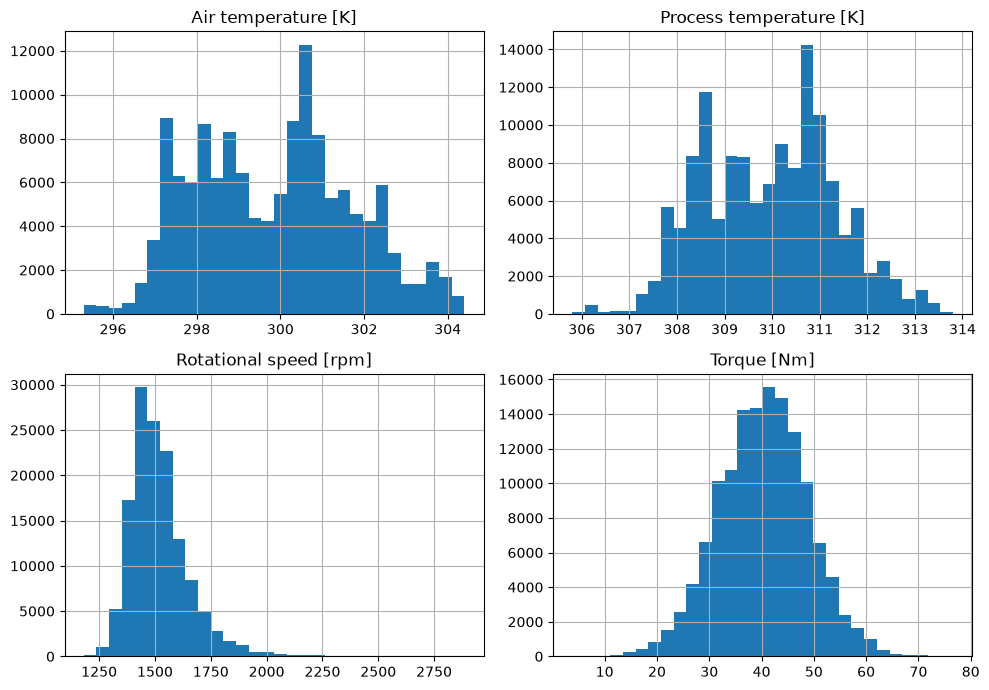

In [23]:
# Histogram
import matplotlib.pyplot as plt

cols = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]"
]

df[cols].hist(figsize=(10, 7), bins=30)
plt.tight_layout()
plt.show()

### Observation

1. Air Temperature: Multiple peaks; most values lie between 297–303 K. No obvious extreme outliers.

2. Process Temperature: Multiple peaks; most values lie between 308–312 K. No obvious extreme outliers.

3. Rotational Speed: Right-skewed; most values lie between 1,350–1,700 rpm. Potential high-value outliers are present.

4. Torque: Approximately normally distributed; most values lie between 30–50 Nm. Some extreme values may be present.

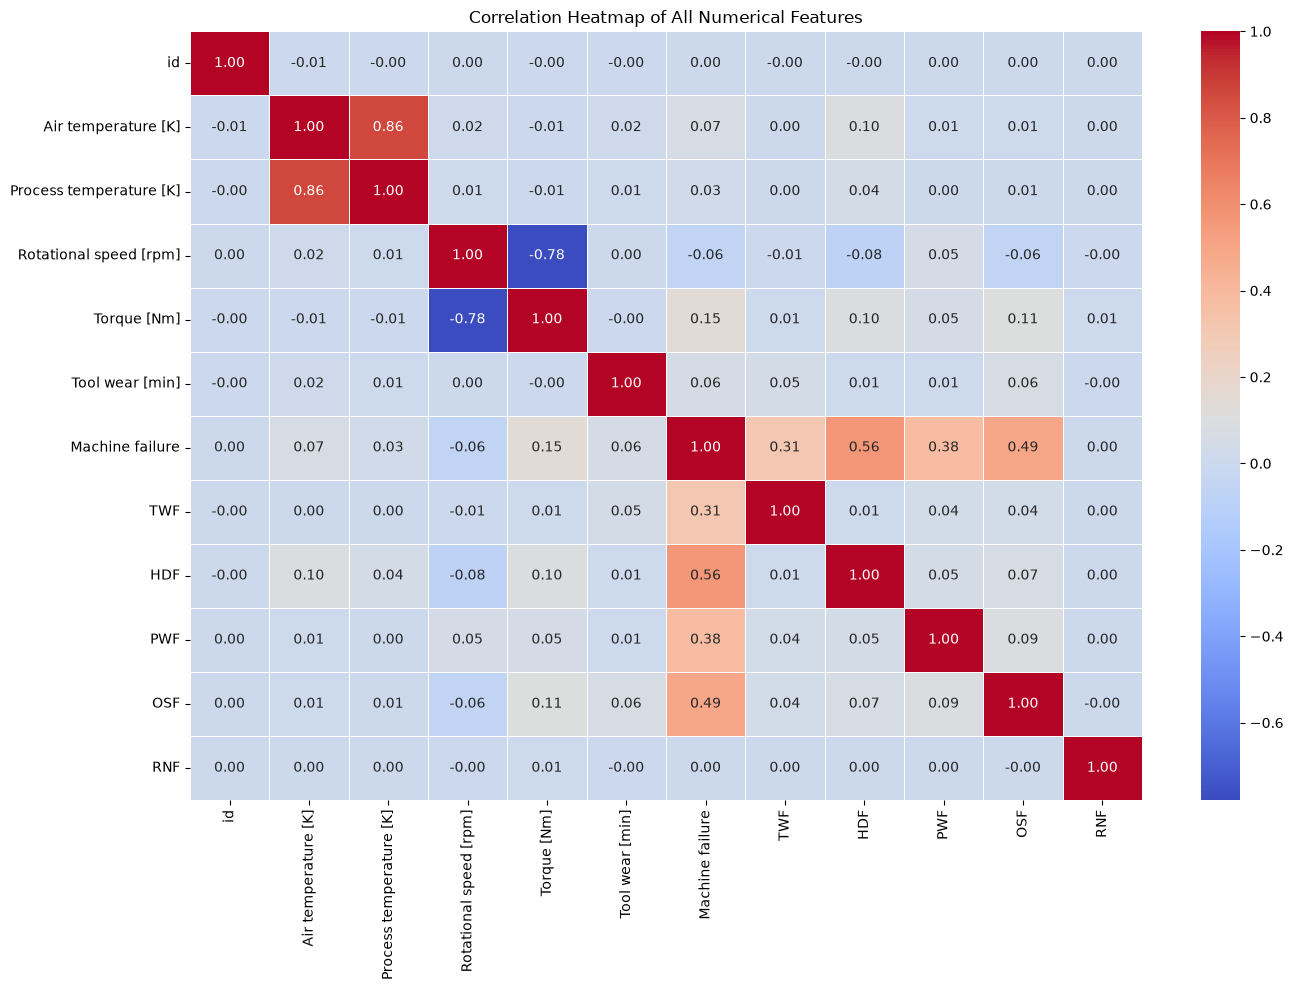

In [25]:
# Correlation 
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 10))

sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of All Numerical Features")
plt.tight_layout()
plt.show()


### Obesrvation 
1. Air Temperature and Process Temperature: Strong positive correlation (0.86).

2. Rotational Speed and Torque: Strong negative correlation (-0.78).
3. Machine Failure and HDF: Moderate positive correlation (0.56).
4. Machine Failure and OSF: Moderate positive correlation (0.49).
5. Machine Failure and PWF: Weak positive correlation (0.38).
Other features: Show weak or almost no correlation.

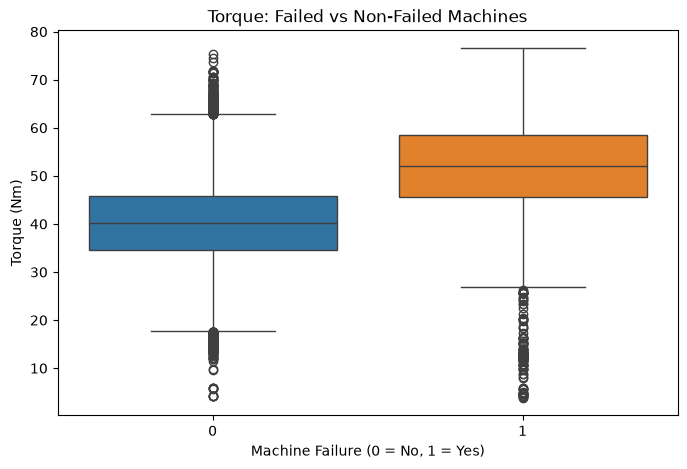

In [27]:
# Box plot
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Machine failure",
    y="Torque [Nm]",
    hue="Machine failure",
    legend=False
)

plt.title("Torque: Failed vs Non-Failed Machines")
plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
plt.ylabel("Torque (Nm)")
plt.show()

### Observation 

1. Median: Failed machines (1) have higher median torque (52 Nm) than non-failed machines (0) (40 Nm).
2. Spread: Failed machines show a wider range of torque values.
3. Outliers: Both groups contain outliers.

In [29]:
con = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

In [30]:
# Outlier Handling Using IQR Method

df_clean = df.copy()

for col in con:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)

    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    df_clean = df_clean[
        (df_clean[col] >= lower) &
        (df_clean[col] <= upper)
    ]

print("Original shape:", df.shape)
print("Shape after removing outliers:", df_clean.shape)
print("Total rows removed:", len(df) - len(df_clean))

Original shape: (136429, 14)
Shape after removing outliers: (130618, 14)
Total rows removed: 5811


### Observation
1. The original dataset contained 136,429 rows and 14 columns.
2. The IQR method removed 5,811 rows containing outliers.
3. After outlier removal, the dataset contained 130,618 rows and 14 columns.
4. Approximately 4.26% of the rows were removed.

### Separate X and Y Features 

In [34]:
X = df_clean.drop(
    columns=["Machine failure", "id", "Product ID", "TWF", "HDF", "PWF", "OSF", "RNF"]
)

y = df_clean["Machine failure"]

print("X shape:", X.shape)
print("y shape:", y.shape)
display(X.head())
display(y.head())

X shape: (130618, 6)
y shape: (130618,)


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
0,L,300.6,309.6,1596,36.1,140
1,M,302.6,312.1,1759,29.1,200
3,L,301.0,310.9,1524,44.3,197
4,M,298.0,309.0,1641,35.4,34
5,M,298.4,308.9,1429,42.1,65


0    0
1    0
3    0
4    0
5    0
Name: Machine failure, dtype: int64

#### By Observing y data is Imbalanced

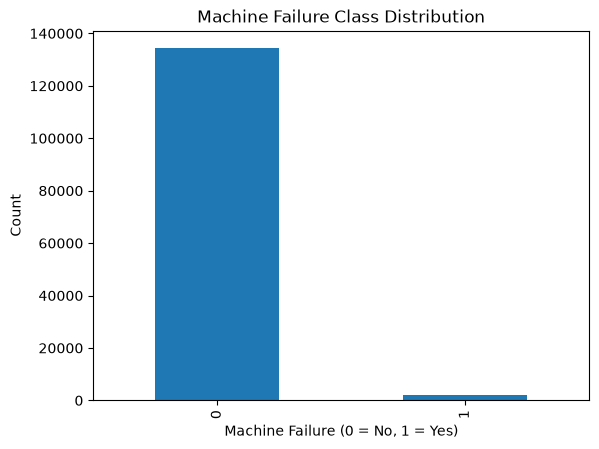

In [32]:
import matplotlib.pyplot as plt

df["Machine failure"].value_counts().sort_index().plot(kind="bar")

plt.title("Machine Failure Class Distribution")
plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.show()

**Analysis**

- Class 0 (No Failure) has 134,281 records.
- Class 1 (Failure) has 2,148 records.
- The dataset is highly imbalanced, as most records belong to Class 0

### Splitting The Data on Basis of Stratified Split


In [47]:
from sklearn.model_selection import train_test_split

xtrain, xtest, ytrain, ytest = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", xtrain.shape)
print("X_test:", xtest.shape)
print("y_train:", ytrain.shape)
print("y_test:", ytest.shape)

X_train: (104494, 7)
X_test: (26124, 7)
y_train: (104494,)
y_test: (26124,)


In [48]:
xtrain.shape

(104494, 7)

In [49]:
ytrain.shape

(104494,)

In [41]:
xtrain.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
23544,L,302.6,310.5,1615,34.2,123
28147,L,301.5,310.5,1451,43.5,77
101374,M,297.5,308.2,1424,53.9,120
69024,L,297.4,308.5,1583,32.5,148
52609,M,298.2,308.7,1499,38.7,62


In [42]:
ytrain.head()

23544     0
28147     0
101374    0
69024     0
52609     0
Name: Machine failure, dtype: int64

In [43]:
xtest.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
88110,L,298.8,309.6,1639,27.5,153
6576,L,302.9,312.2,1492,43.5,42
67713,L,297.4,309.0,1469,44.9,149
33881,L,302.4,310.2,1709,27.1,64
48514,L,298.0,307.7,1430,50.8,49


### Feature Engineering

In [50]:
X["Temperature Difference"] = (
    X["Process temperature [K]"] -
    X["Air temperature [K]"]
)

print(X.head())

  Type  Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  \
0    L                300.6                    309.6                    1596   
1    M                302.6                    312.1                    1759   
3    L                301.0                    310.9                    1524   
4    M                298.0                    309.0                    1641   
5    M                298.4                    308.9                    1429   

   Torque [Nm]  Tool wear [min]  Temperature Difference  
0         36.1              140                     9.0  
1         29.1              200                     9.5  
3         44.3              197                     9.9  
4         35.4               34                    11.0  
5         42.1               65                    10.5  


In [51]:
cat = list(X_train.select_dtypes(include="str").columns)
con = list(X_train.select_dtypes(include="number").columns)

print("Categorical columns:", cat)
print("Numerical columns:", con)

Categorical columns: ['Type']
Numerical columns: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Temperature Difference']


In [53]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

cat = list(X.select_dtypes(include="str").columns)
con = list(X.select_dtypes(include="number").columns)

num_pipe = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler()
)

cat_pipe = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(handle_unknown="ignore", sparse_output=False)
)

pre = ColumnTransformer([
    ("cat", cat_pipe, cat),
    ("con", num_pipe, con)
])
pre

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('con', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

In [54]:
pre.fit(xtrain)

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('con', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

In [55]:

xtrain_pre = pre.transform(xtrain)
xtest_pre = pre.transform(xtest)

### Model Building 